# House Price Prediction Using Linear Regression

## Oasis Infobyte — Data Analytics Internship
### Level 2 — Task 1

## Project Objective

The objective of this project is to build and evaluate a machine learning regression model that predicts house prices using property characteristics such as area, bedrooms, bathrooms, number of stories, parking availability and other housing features.

The project includes:

- Data inspection
- Exploratory Data Analysis
- Missing-value checks
- Categorical encoding
- Correlation analysis
- Feature selection
- Train-test splitting
- Linear Regression modelling
- Model evaluation using MSE, RMSE and R²
- Actual vs predicted price analysis
- Residual analysis
- Coefficient interpretation

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [75]:
url = "https://raw.githubusercontent.com/Komalharini237/Housing-Case-Study-Multiple-Linear-Regression/main/Housing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 1. Initial Data Inspection

The dataset is first inspected to understand its dimensions, feature names, data types and overall structure before building the predictive model.

In [76]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
for column in df.columns:
    print("-", column)

Number of rows: 545
Number of columns: 13

Column Names:
- price
- area
- bedrooms
- bathrooms
- stories
- mainroad
- guestroom
- basement
- hotwaterheating
- airconditioning
- parking
- prefarea
- furnishingstatus


In [77]:
df.head(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [79]:
df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
mainroad,object
guestroom,object
basement,object
hotwaterheating,object
airconditioning,object


## 2. Missing Value Analysis

Missing values are checked before model development because incomplete observations can affect both model training and prediction accuracy.

In [80]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_values

,Missing Values,Missing Percentage
price,0,0.0
area,0,0.0
bedrooms,0,0.0
bathrooms,0,0.0
stories,0,0.0
mainroad,0,0.0
guestroom,0,0.0
basement,0,0.0
hotwaterheating,0,0.0
airconditioning,0,0.0


In [81]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


### Observation

The dataset contains no missing values, so no missing-value imputation was required before modelling.

In [82]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [83]:
if duplicate_count > 0:
    df = df.drop_duplicates().copy()
    print(f"{duplicate_count} duplicate rows removed.")
else:
    print("No duplicate rows found.")

No duplicate rows found.


## 3. Descriptive Statistics

Descriptive statistics provide an overview of the numerical housing characteristics and the distribution of house prices.

In [84]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [85]:
numerical_columns = [
    "price",
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking"
]

statistics_summary = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Standard Deviation": df[numerical_columns].std(),
    "Minimum": df[numerical_columns].min(),
    "Maximum": df[numerical_columns].max()
})

statistics_summary.round(2)

,Mean,Median,Standard Deviation,Minimum,Maximum
price,4766729.25,4340000.0,1870439.62,1750000,13300000
area,5150.54,4600.0,2170.14,1650,16200
bedrooms,2.97,3.0,0.74,1,6
bathrooms,1.29,1.0,0.50,1,4
stories,1.81,2.0,0.87,1,4
parking,0.69,0.0,0.86,0,3


## 4. House Price Distribution

The target variable, house price, is examined to understand its overall distribution and whether extremely high or low values are present.

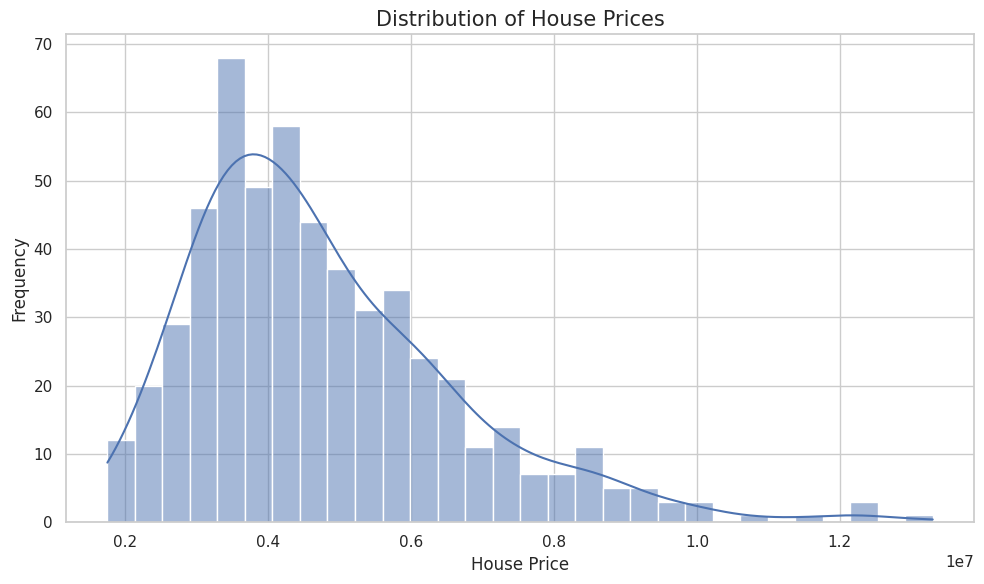

In [86]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price",
    bins=30,
    kde=True
)

plt.title("Distribution of House Prices", fontsize=15)
plt.xlabel("House Price")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

### Observation

The price distribution shows how house values are spread across the dataset.

Examining the target distribution is important because heavily skewed prices or extreme values may influence the behaviour of a Linear Regression model.

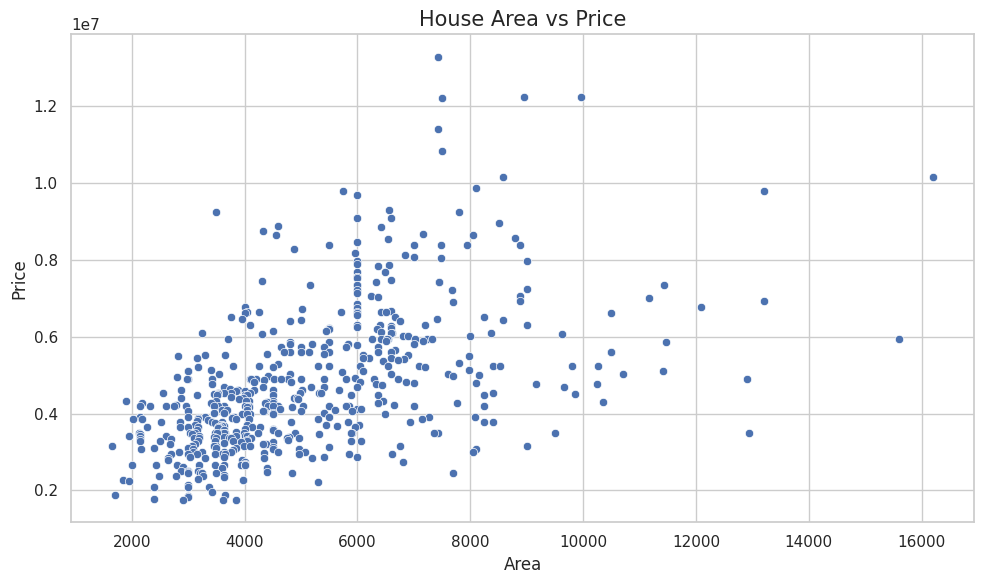

In [87]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="area",
    y="price"
)

plt.title("House Area vs Price", fontsize=15)
plt.xlabel("Area")
plt.ylabel("Price")
plt.tight_layout()

plt.show()

### Observation

The scatter plot examines whether larger houses tend to have higher prices.

A positive relationship would suggest that area is likely to be an important predictor in the regression model.

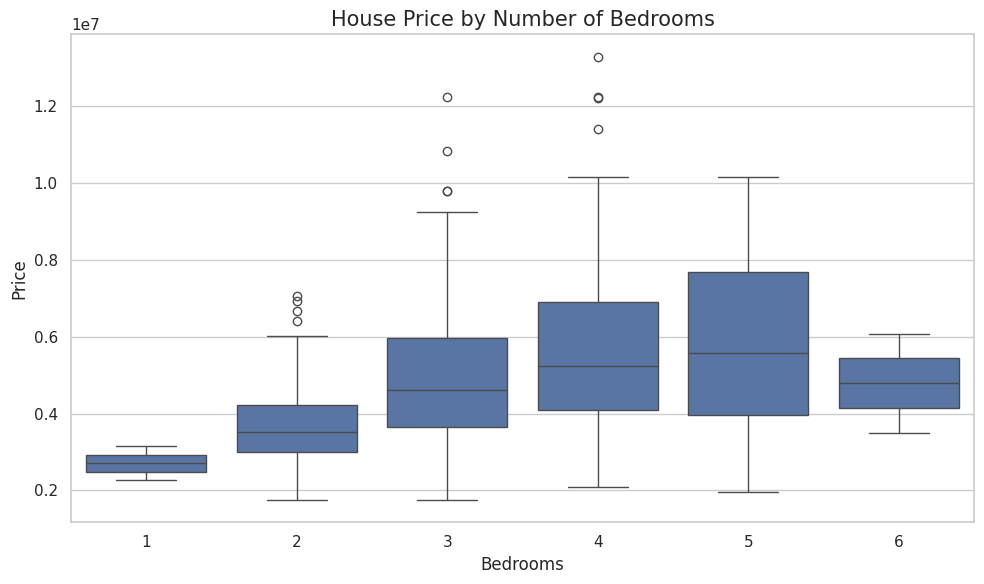

In [88]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="bedrooms",
    y="price"
)

plt.title("House Price by Number of Bedrooms", fontsize=15)
plt.xlabel("Bedrooms")
plt.ylabel("Price")
plt.tight_layout()

plt.show()

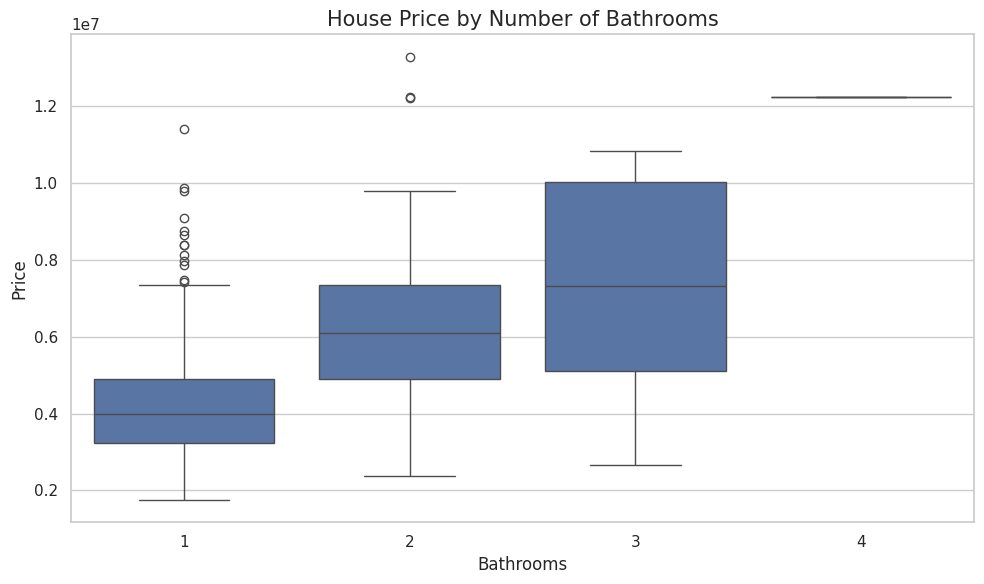

In [89]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="bathrooms",
    y="price"
)

plt.title("House Price by Number of Bathrooms", fontsize=15)
plt.xlabel("Bathrooms")
plt.ylabel("Price")
plt.tight_layout()

plt.show()

### Observation

Bedroom and bathroom analysis helps determine whether properties with more rooms tend to command higher prices.

These features are likely candidates for inclusion in the prediction model.

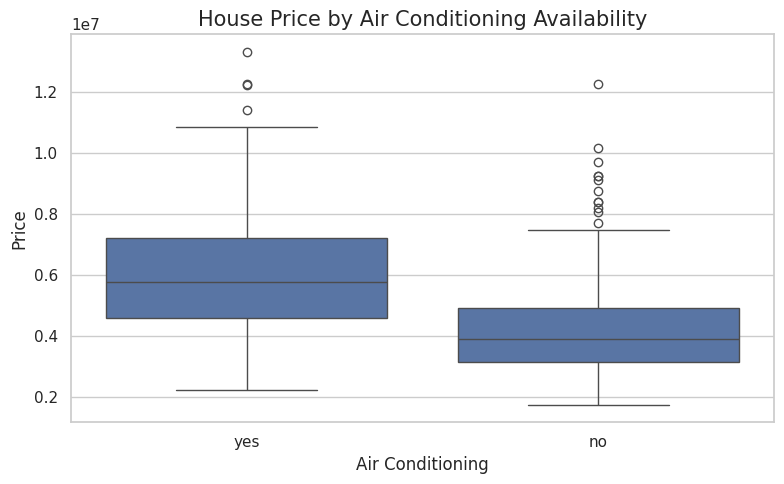

In [90]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="airconditioning",
    y="price"
)

plt.title("House Price by Air Conditioning Availability", fontsize=15)
plt.xlabel("Air Conditioning")
plt.ylabel("Price")
plt.tight_layout()

plt.show()

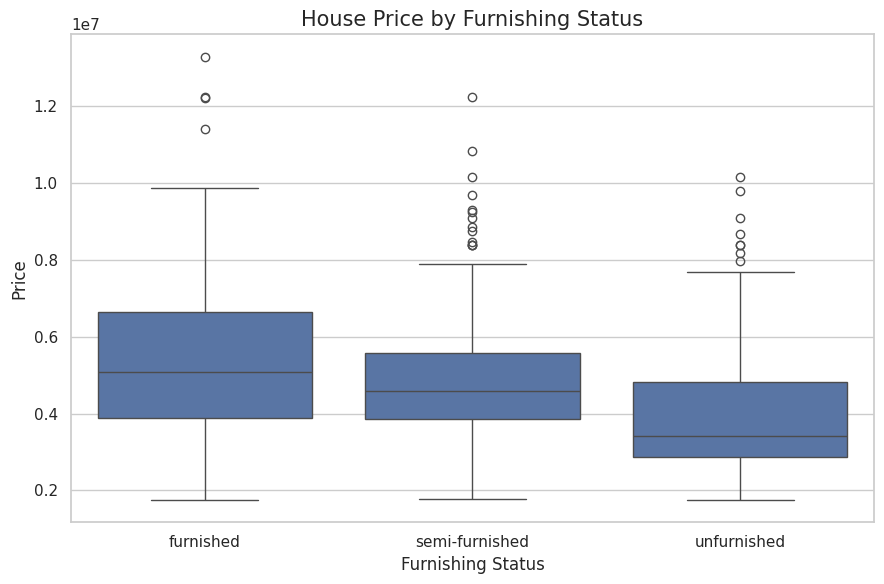

In [91]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="furnishingstatus",
    y="price"
)

plt.title("House Price by Furnishing Status", fontsize=15)
plt.xlabel("Furnishing Status")
plt.ylabel("Price")
plt.tight_layout()

plt.show()

### Observation

Categorical housing features such as air conditioning and furnishing status may also influence price.

These features cannot be used directly by Linear Regression in text form, so they will be encoded numerically before modelling.

In [92]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

correlation_matrix.round(2)

,price,area,bedrooms,bathrooms,stories,parking
price,1.00,0.54,0.37,0.52,0.42,0.38
area,0.54,1.00,0.15,0.19,0.08,0.35
bedrooms,0.37,0.15,1.00,0.37,0.41,0.14
bathrooms,0.52,0.19,0.37,1.00,0.33,0.18
stories,0.42,0.08,0.41,0.33,1.00,0.05
parking,0.38,0.35,0.14,0.18,0.05,1.00


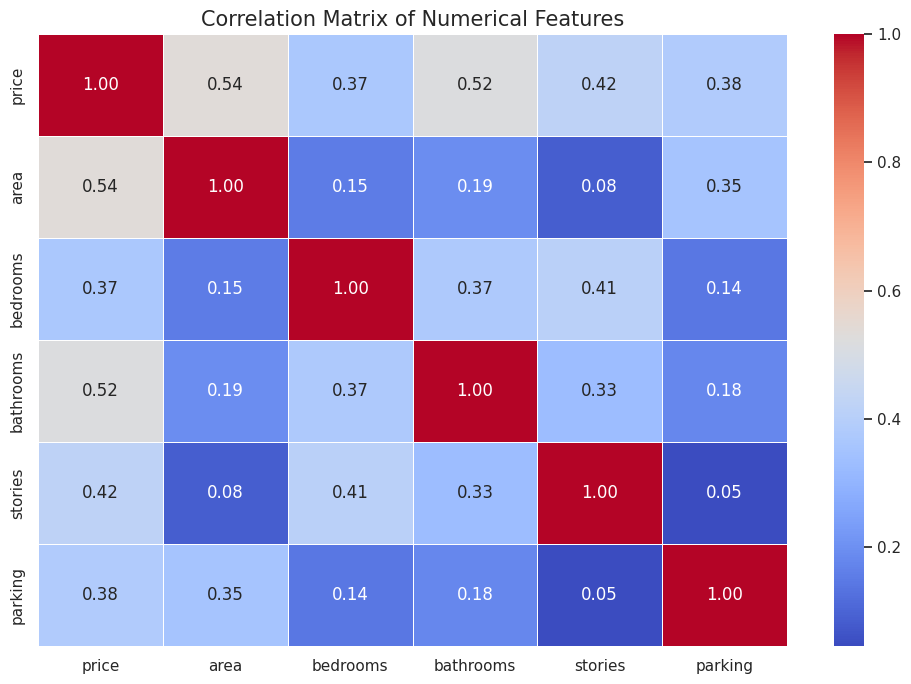

In [93]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features", fontsize=15)
plt.tight_layout()

plt.show()

### Observation

The correlation matrix shows which numerical variables have the strongest linear relationships with house price.

Features with stronger positive correlations with price are likely to contribute more strongly to the Linear Regression model.

## 5. Feature Selection Discussion

House price is expected to be influenced by both physical size and property characteristics.

The main candidate predictors include:

- Area
- Bedrooms
- Bathrooms
- Stories
- Parking
- Main road access
- Guest room availability
- Basement availability
- Hot water heating
- Air conditioning
- Preferred area
- Furnishing status

Area, bathrooms and other structural characteristics are likely to have a direct relationship with price, while amenity and location features may provide additional explanatory value.

All available features will initially be included after categorical encoding so that the model can estimate their individual contributions.

## 6. Categorical Encoding

Machine learning models such as Linear Regression require numerical input.

Categorical variables are therefore converted into numeric indicator variables using One-Hot Encoding.

The `drop_first=True` option is used to avoid redundant dummy variables.

In [94]:
encoded_df = pd.get_dummies(
    df,
    drop_first=True
)

print("Encoded dataset shape:", encoded_df.shape)

encoded_df.head()

Encoded dataset shape: (545, 14)


,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,2,True,False,False,False,True,True,False,False
1,12250000,8960,4,4,4,3,True,False,False,False,True,False,False,False
2,12250000,9960,3,2,2,2,True,False,True,False,False,True,True,False
3,12215000,7500,4,2,2,3,True,False,True,False,True,True,False,False
4,11410000,7420,4,1,2,2,True,True,True,False,True,False,False,False


In [95]:
encoded_df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
parking,int64
mainroad_yes,bool
guestroom_yes,bool
basement_yes,bool
hotwaterheating_yes,bool


In [96]:
bool_columns = encoded_df.select_dtypes(include="bool").columns

encoded_df[bool_columns] = encoded_df[bool_columns].astype(int)

encoded_df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
parking,int64
mainroad_yes,int64
guestroom_yes,int64
basement_yes,int64
hotwaterheating_yes,int64


## 7. Correlation with House Price

After categorical encoding, the relationships between all available features and house price can be compared numerically.

In [97]:
price_correlations = (
    encoded_df.corr()["price"]
    .sort_values(ascending=False)
)

price_correlations

,price
price,1.000000
area,0.535997
bathrooms,0.517545
airconditioning_yes,0.452954
stories,0.420712
parking,0.384394
bedrooms,0.366494
prefarea_yes,0.329777
mainroad_yes,0.296898
guestroom_yes,0.255517


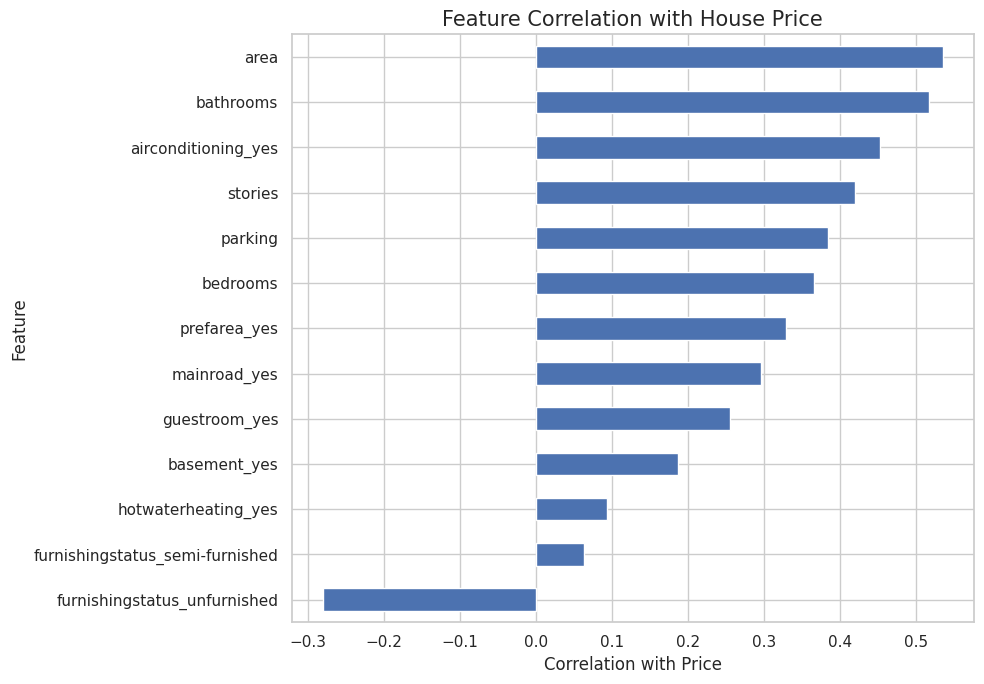

In [98]:
plt.figure(figsize=(10, 7))

price_correlations.drop("price").sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with House Price", fontsize=15)
plt.xlabel("Correlation with Price")
plt.ylabel("Feature")
plt.tight_layout()

plt.show()

### Observation

The correlation analysis helps identify which encoded housing features have the strongest linear relationships with price.

Features with stronger positive correlations may contribute more strongly to the Linear Regression model, although correlation alone does not prove causation.

## 8. Feature and Target Definition

The target variable is `price`.

All remaining encoded columns are used as predictor features.

In [99]:
X = encoded_df.drop("price", axis=1)
y = encoded_df["price"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

Feature matrix shape: (545, 13)
Target shape: (545,)

Features used:
['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'mainroad_yes', 'guestroom_yes', 'basement_yes', 'hotwaterheating_yes', 'airconditioning_yes', 'prefarea_yes', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


## 9. Train-Test Split

The dataset is divided into training and testing sets.

80% of the data is used to train the model and 20% is reserved for evaluating performance on unseen data.

A fixed random state is used to make the results reproducible.

In [100]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (436, 13)
Testing features: (109, 13)
Training target: (436,)
Testing target: (109,)


## 10. Linear Regression Model

A multiple Linear Regression model is trained using the training dataset.

The model estimates a coefficient for each property feature and uses these coefficients to predict house prices.

In [101]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [102]:
y_pred = linear_model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


In [103]:
prediction_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

prediction_comparison.head(10)

,Actual Price,Predicted Price
0,4060000,5.164654e+06
1,6650000,7.224722e+06
2,3710000,3.109863e+06
3,6440000,4.612075e+06
4,2800000,3.294646e+06
5,4900000,3.532275e+06
6,5250000,5.611775e+06
7,4543000,6.368146e+06
8,2450000,2.722857e+06
9,3353000,2.629406e+06


## 11. Model Evaluation

The model is evaluated using three regression metrics:

- **Mean Squared Error (MSE):** measures the average squared prediction error.
- **Root Mean Squared Error (RMSE):** expresses prediction error in the same units as house price.
- **R² Score:** measures the proportion of variation in house prices explained by the model.

A lower MSE and RMSE indicate better predictions, while an R² value closer to 1 indicates stronger explanatory performance.

In [104]:
mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)

print("========== LINEAR REGRESSION PERFORMANCE ==========")

print(f"MSE: {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

========== LINEAR REGRESSION PERFORMANCE ==========
MSE: 1,754,318,687,330.66
RMSE: 1,324,506.96
R² Score: 0.6529


## 12. Actual vs Predicted House Prices

Actual prices are plotted against predicted prices.

If predictions were perfect, all observations would fall directly along the diagonal reference line.

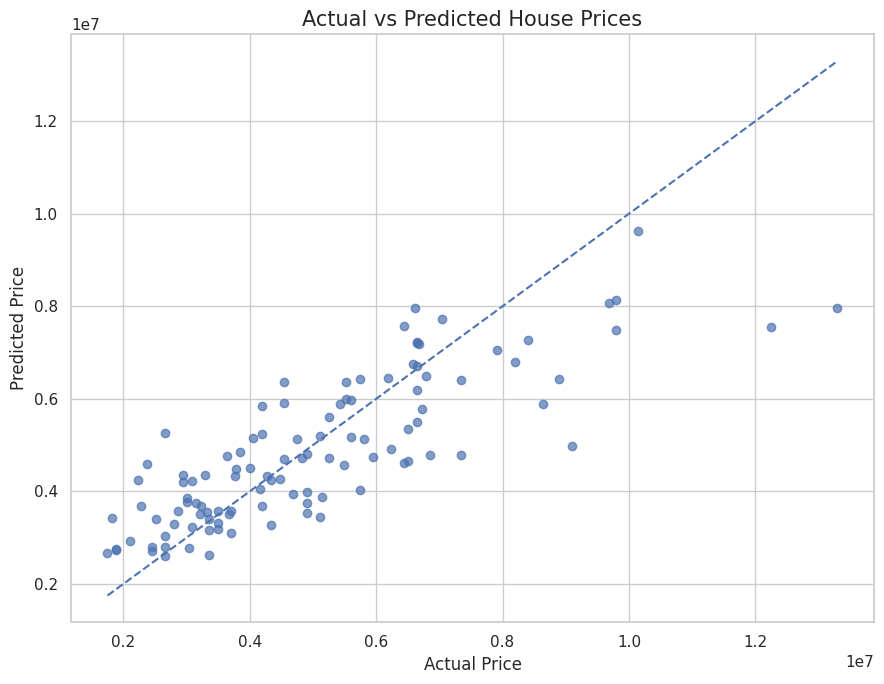

In [105]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

minimum_price = min(
    y_test.min(),
    y_pred.min()
)

maximum_price = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [minimum_price, maximum_price],
    [minimum_price, maximum_price],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices", fontsize=15)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.tight_layout()

plt.show()

### Observation

The closer the points are to the diagonal reference line, the closer the model's predictions are to the actual house prices.

Points further away from the line represent larger prediction errors.

## 13. Residual Analysis

Residuals represent the difference between actual and predicted values.

Residual = Actual Price - Predicted Price

A well-behaved Linear Regression model should generally show residuals distributed around zero without an obvious systematic pattern.

In [106]:
residuals = y_test - y_pred

residual_summary = pd.Series(
    residuals
).describe()

residual_summary

,price
count,1.090000e+02
mean,1.460554e+05
std,1.322510e+06
min,-2.603188e+06
25%,-7.023621e+05
50%,-8.189880e+04
75%,9.234027e+05
max,5.331724e+06


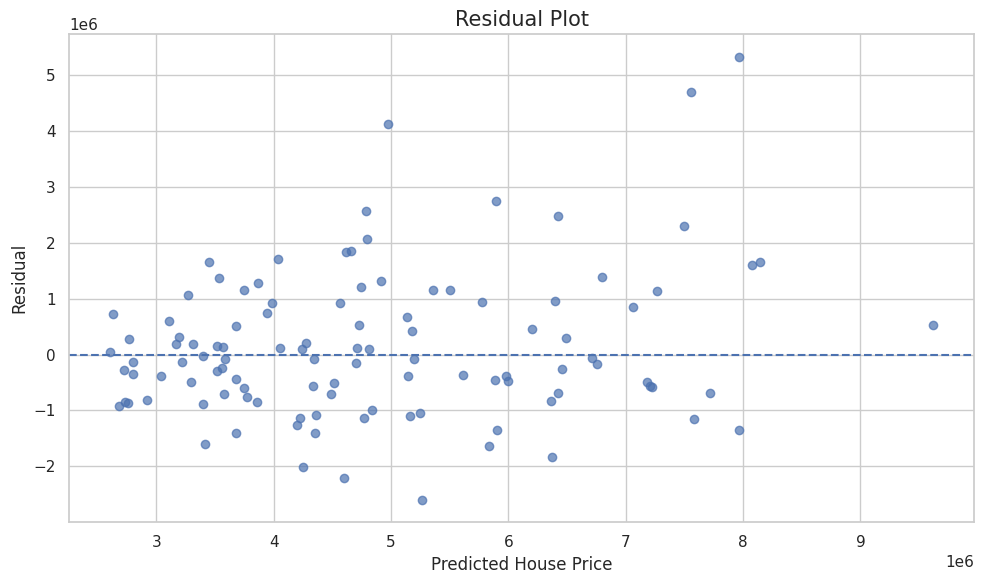

In [107]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Plot", fontsize=15)
plt.xlabel("Predicted House Price")
plt.ylabel("Residual")
plt.tight_layout()

plt.show()

### Observation

The residual plot is used to check whether model errors are randomly distributed.

A random spread around zero suggests that the Linear Regression assumptions are reasonably appropriate.

Clear curves, funnels or other systematic patterns could indicate that the model is missing important relationships in the data.

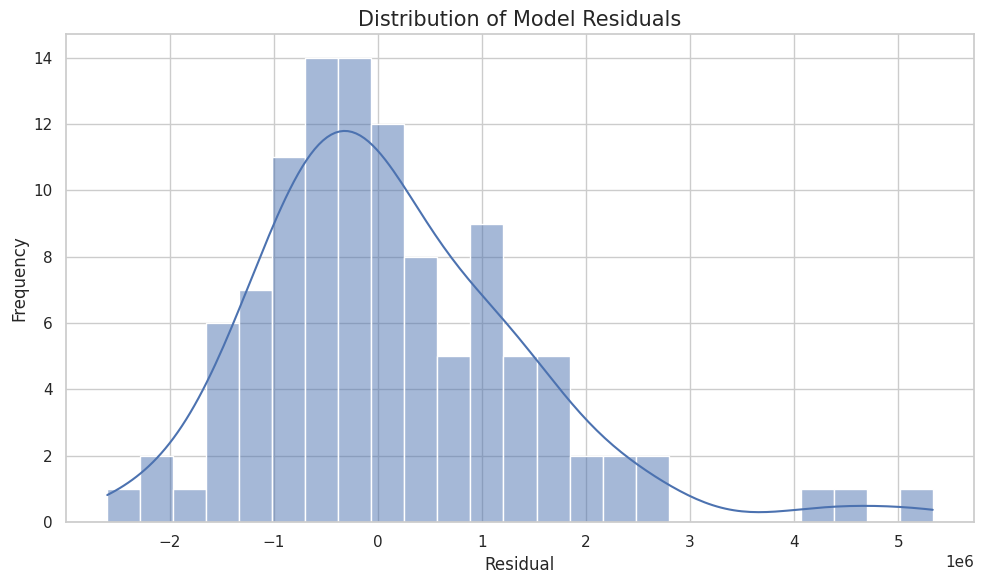

In [108]:
plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=25,
    kde=True
)

plt.title("Distribution of Model Residuals", fontsize=15)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

### Observation

The residual distribution provides another way to inspect prediction errors.

A reasonably centred distribution around zero suggests that the model does not consistently overpredict or underpredict house prices.

## 14. Model Coefficient Analysis

Each Linear Regression coefficient represents the estimated change in house price associated with a one-unit increase in that feature, assuming the other features remain constant.

Positive coefficients indicate an estimated increase in price, while negative coefficients indicate an estimated decrease.

In [109]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

coefficients = coefficients.sort_values(
    "Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
2,bathrooms,1.094445e+06
9,airconditioning_yes,7.914267e+05
8,hotwaterheating_yes,6.846499e+05
10,prefarea_yes,6.298906e+05
3,stories,4.074766e+05
7,basement_yes,3.902512e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
4,parking,2.248419e+05
1,bedrooms,7.677870e+04


In [110]:
print("Features with the highest positive coefficients:")

coefficients.head(10)

Features with the highest positive coefficients:


,Feature,Coefficient
2,bathrooms,1.094445e+06
9,airconditioning_yes,7.914267e+05
8,hotwaterheating_yes,6.846499e+05
10,prefarea_yes,6.298906e+05
3,stories,4.074766e+05
7,basement_yes,3.902512e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
4,parking,2.248419e+05
1,bedrooms,7.677870e+04


In [111]:
print("Features with the most negative coefficients:")

coefficients.tail(10)

Features with the most negative coefficients:


,Feature,Coefficient
10,prefarea_yes,629890.565313
3,stories,407476.594985
7,basement_yes,390251.176181
5,mainroad_yes,367919.947680
6,guestroom_yes,231610.037176
4,parking,224841.913277
1,bedrooms,76778.701634
0,area,235.968805
11,furnishingstatus_semi-furnished,-126881.817585
12,furnishingstatus_unfurnished,-413645.062228


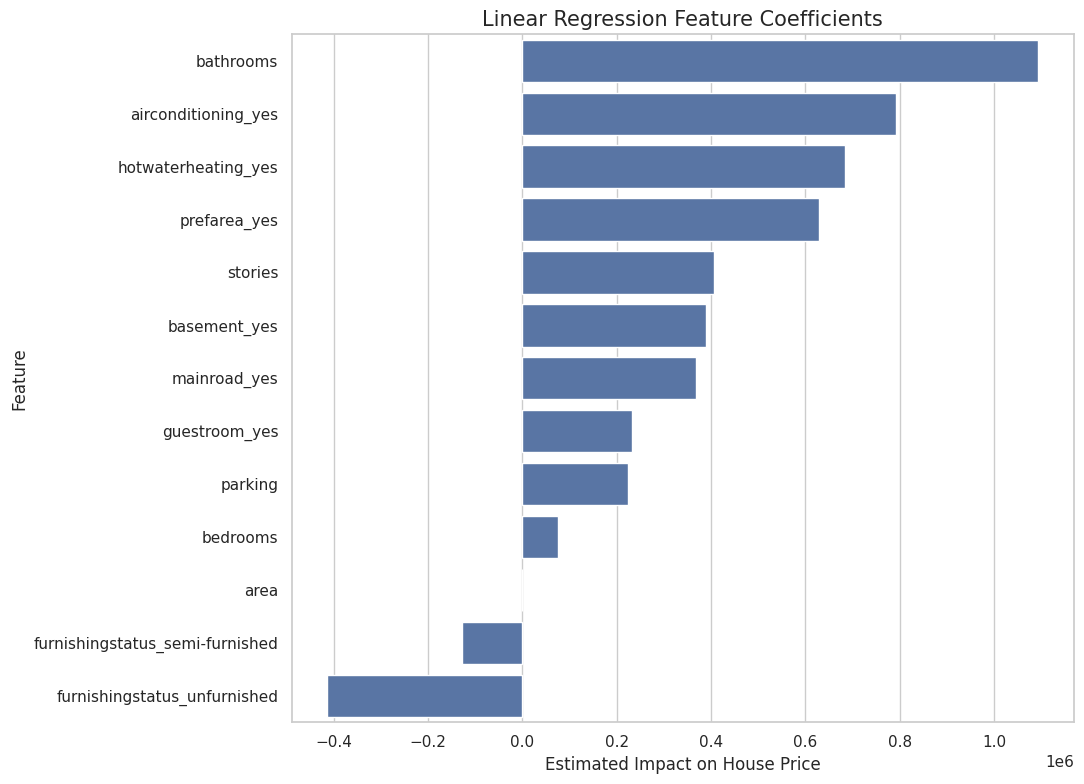

In [112]:
plt.figure(figsize=(11, 8))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression Feature Coefficients", fontsize=15)
plt.xlabel("Estimated Impact on House Price")
plt.ylabel("Feature")
plt.tight_layout()

plt.show()

### Observation

Coefficient analysis helps explain how the model uses each housing feature when estimating price.

Features with large positive coefficients are associated with higher predicted prices after controlling for the other variables.

Negative coefficients indicate features associated with lower predicted prices relative to their reference category or baseline.

In [113]:
model_performance = pd.DataFrame({
    "Metric": [
        "Mean Squared Error",
        "Root Mean Squared Error",
        "R² Score"
    ],
    "Linear Regression": [
        mse,
        rmse,
        r2
    ]
})

model_performance

,Metric,Linear Regression
0,Mean Squared Error,1.754319e+12
1,Root Mean Squared Error,1.324507e+06
2,R² Score,6.529243e-01


In [114]:
top_positive_feature = coefficients.iloc[0]["Feature"]
top_positive_coefficient = coefficients.iloc[0]["Coefficient"]

top_negative_feature = coefficients.iloc[-1]["Feature"]
top_negative_coefficient = coefficients.iloc[-1]["Coefficient"]

print("========== MODEL SUMMARY ==========")

print(f"Training observations: {len(X_train)}")
print(f"Testing observations: {len(X_test)}")

print()

print(f"MSE: {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

print()

print(
    f"Strongest Positive Coefficient: "
    f"{top_positive_feature} "
    f"({top_positive_coefficient:,.2f})"
)

print(
    f"Most Negative Coefficient: "
    f"{top_negative_feature} "
    f"({top_negative_coefficient:,.2f})"
)

========== MODEL SUMMARY ==========
Training observations: 436
Testing observations: 109

MSE: 1,754,318,687,330.66
RMSE: 1,324,506.96
R² Score: 0.6529

Strongest Positive Coefficient: bathrooms (1,094,444.79)
Most Negative Coefficient: furnishingstatus_unfurnished (-413,645.06)


In [115]:
top_positive_feature = coefficients.iloc[0]["Feature"]
top_positive_coefficient = coefficients.iloc[0]["Coefficient"]

top_negative_feature = coefficients.iloc[-1]["Feature"]
top_negative_coefficient = coefficients.iloc[-1]["Coefficient"]

print("========== MODEL SUMMARY ==========")

print(f"Training observations: {len(X_train)}")
print(f"Testing observations: {len(X_test)}")

print()

print(f"MSE: {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

print()

print(
    f"Strongest Positive Coefficient: "
    f"{top_positive_feature} "
    f"({top_positive_coefficient:,.2f})"
)

print(
    f"Most Negative Coefficient: "
    f"{top_negative_feature} "
    f"({top_negative_coefficient:,.2f})"
)

========== MODEL SUMMARY ==========
Training observations: 436
Testing observations: 109

MSE: 1,754,318,687,330.66
RMSE: 1,324,506.96
R² Score: 0.6529

Strongest Positive Coefficient: bathrooms (1,094,444.79)
Most Negative Coefficient: furnishingstatus_unfurnished (-413,645.06)


# 15. Model Interpretation

The Linear Regression model was trained using 436 observations and evaluated on 109 unseen test observations.

The model achieved an R² score of 0.6529.

This means that approximately 65.29% of the variation in house prices is explained by the features included in the model.

The Root Mean Squared Error (RMSE) was approximately 1,324,506.96. This represents the typical size of the model's prediction error in the same units as house price.

The model therefore demonstrates useful predictive ability, although a meaningful portion of house-price variation remains unexplained.

The strongest positive coefficient was associated with the number of bathrooms. Holding other variables constant, additional bathrooms were associated with a substantial increase in predicted house price.

The strongest negative coefficient was associated with unfurnished properties. Compared with the reference furnishing category, unfurnished properties were associated with lower predicted prices.

These findings suggest that both structural property features and finishing characteristics contribute significantly to housing prices.

# 17. Conclusion

This project successfully developed and evaluated a multiple Linear Regression model for predicting house prices.

The workflow included exploratory data analysis, categorical encoding, feature selection, an 80/20 train-test split, model training, prediction, performance evaluation, residual analysis and coefficient interpretation.

The final Linear Regression model achieved an R² score of 0.6529, meaning that approximately 65.29% of the variation in house prices was explained by the selected property features.

The model achieved an RMSE of approximately 1,324,506.96.

Coefficient analysis showed that the number of bathrooms had the strongest positive association with house price, while unfurnished properties had the strongest negative association relative to the reference furnishing category.

Overall, the project demonstrates how machine learning can be used to estimate property values and identify features that are associated with higher or lower house prices.

Although the model provides useful predictive insight, further improvements could include additional location-based features, property condition information, larger datasets and alternative modelling techniques.

In [116]:
from sklearn.linear_model import Ridge

In [117]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("========== RIDGE REGRESSION PERFORMANCE ==========")
print(f"MSE: {ridge_mse:,.2f}")
print(f"RMSE: {ridge_rmse:,.2f}")
print(f"R² Score: {ridge_r2:.4f}")

========== RIDGE REGRESSION PERFORMANCE ==========
MSE: 1,756,474,279,575.29
RMSE: 1,325,320.44
R² Score: 0.6525


In [118]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression"
    ],
    "MSE": [
        mse,
        ridge_mse
    ],
    "RMSE": [
        rmse,
        ridge_rmse
    ],
    "R²": [
        r2,
        ridge_r2
    ]
})

model_comparison

,Model,MSE,RMSE,R²
0,Linear Regression,1.754319e+12,1.324507e+06,0.652924
1,Ridge Regression,1.756474e+12,1.325320e+06,0.652498


### Model Comparison Interpretation

Linear Regression slightly outperformed Ridge Regression on the test dataset.

The Linear Regression model achieved an R² score of 0.6529 compared with 0.6525 for Ridge Regression.

Linear Regression also produced a slightly lower RMSE of approximately 1,324,507, compared with approximately 1,325,320 for Ridge Regression.

The difference between the two models is very small, indicating that Ridge regularisation did not provide a meaningful improvement in predictive performance for this dataset.

Based on these results, Linear Regression is selected as the preferred final model because it achieved slightly better test performance while remaining straightforward to interpret.

## 18. Model Comparison

Linear Regression was compared with Ridge Regression as a regularised alternative.

The model with the lower RMSE and higher R² score provides the stronger predictive performance on the test dataset.

Ridge Regression can be useful when predictors are correlated because regularisation reduces the magnitude of model coefficients and can improve model stability.

# 19. Final Conclusion

This project developed and evaluated machine learning models for predicting house prices using a combination of structural property characteristics, amenities and furnishing information.

The analysis began with exploratory data analysis to understand the distribution of house prices and relationships between property features and the target variable.

Categorical features were transformed using One-Hot Encoding, after which the dataset was divided into an 80% training set and a 20% testing set.

A multiple Linear Regression model was trained on 436 observations and evaluated using 109 unseen observations.

The Linear Regression model achieved:

- R² Score: 0.6529
- RMSE: approximately 1,324,507
- MSE: approximately 1.754 trillion

This means that the model explains approximately 65.29% of the variation in house prices within the test data.

Coefficient analysis found that bathrooms had the strongest positive model coefficient, while unfurnished properties had the strongest negative coefficient relative to the reference furnishing category.

A Ridge Regression model was also trained as a regularised comparison model.

Ridge Regression achieved an R² score of 0.6525 and an RMSE of approximately 1,325,320.

Because Linear Regression produced a slightly higher R² and slightly lower prediction error, it was selected as the preferred model.

Overall, the project demonstrates that multiple property characteristics can provide meaningful predictive information about house prices. However, the remaining unexplained variation and prediction error indicate that additional factors such as precise location, neighbourhood characteristics, property condition and market conditions could further improve future models.

In [ ]:
final_results = pd.DataFrame({
    "Metric": [
        "Training Observations",
        "Testing Observations",
        "Linear Regression R²",
        "Linear Regression RMSE",
        "Ridge Regression R²",
        "Ridge Regression RMSE",
        "Best Model",
        "Strongest Positive Feature",
        "Strongest Negative Feature"
    ],
    "Result": [
        len(X_train),
        len(X_test),
        round(r2, 4),
        round(rmse, 2),
        round(ridge_r2, 4),
        round(ridge_rmse, 2),
        "Linear Regression",
        top_positive_feature,
        top_negative_feature
    ]
})

final_results